# Advanced Cloud Clearing in Sentinel-2: combining spectral and clustering approaches

Our goal here is to prepare a Sentinel-2 image over a region of interest and create a cloud-clearing function that uses both:
- Spectral characteristics of clouds (e.g., high reflectance in blue, low in SWIR)
- A clustering algorithm (e.g., k-means or DBSCAN on pixel features) to find and expand cloud-masked areas to include neighboring “cloudy-ish” pixels.

My intent is that by the end of this lab you have a function that you can then use in many of your project workflows to ensure that the data you are using is as free of clouds as possible (you will need to re-design it if apply to imagery other than Sentinel 2).

The overview of our workflow is to:
- Load and filter Sentinel-2 surface reflectance imagery in Earth Engine.
- Apply the s2cloudless cloud probability algorithm.
- Apply a clustering approach to detect “borderline” cloudy pixels near heavy clouds.
- Generate a clean composite for a chosen date range.

We are using this tutorial from Google as the basis of our work: [Sentinel-2 Cloud Masking with s2cloudless](https://developers.google.com/earth-engine/tutorials/community/sentinel-2-s2cloudless).


**NOTE: in this lab whenever we ask you for an visual output, we are expecting you to present it to a publication quality level.**


________________________________________________________________________________
# Implementing S2 Cloudless

In [1]:
# Our usual set up routine ｜ 常规环境准备
!pip install geemap --quiet                          # 安装 geemap（Colab 每次新环境都要装；本机已装则几秒跳过）

import geemap                                        # Earth Engine 的交互地图库（Map 控件）
import geopandas as gpd                              # 地理版 pandas（本 lab 备用，按讲义保留）
import pandas as pd                                  # 表格数据处理（采样点转 DataFrame）
import matplotlib.pyplot as plt                      # 画统计图
import numpy as np                                   # 数值计算
import seaborn as sns                                # 统计绘图库（pairplot 配对图）
from sklearn.cluster import KMeans                   # scikit-learn 的 K-means 聚类器

import ee                                            # Google Earth Engine Python API
import os                                            # 读环境变量：本机/Colab 用不同的 GEE 项目名
EE_PROJECT = os.environ.get('EE_PROJECT', 'geog761-ai')  # 默认用课程项目；本机跑时用环境变量 EE_PROJECT 覆盖
try:                                                 # 先试免弹窗初始化（本机走 gcloud ADC 凭据，不开浏览器）
    ee.Initialize(project=EE_PROJECT)                # 直接初始化 Earth Engine
except Exception:                                    # 失败说明本地没有凭据（Colab 首次运行）
    ee.Authenticate()                                # 弹出浏览器完成 Google 授权
    ee.Initialize(project=EE_PROJECT)                # 授权后再初始化

ERROR: Invalid requirement: '#'

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


First, let us define our area of interest (AOI) and the cloud mask parameters: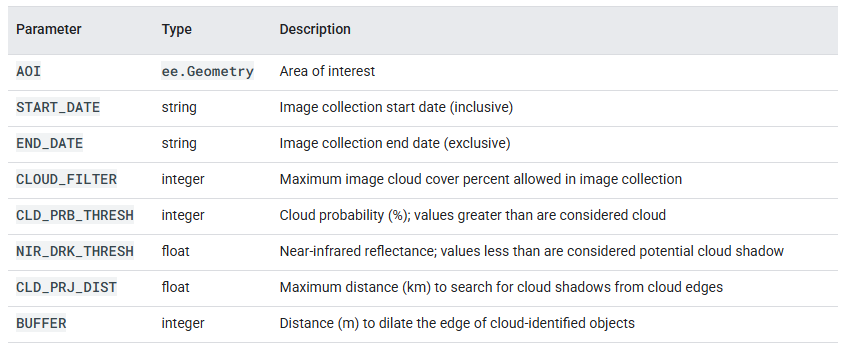

In [2]:
# Control variables ｜ 全局控制参数
AOI = ee.Geometry.Point(174.7633, -36.8485)          # 兴趣区中心：奥克兰市中心（经度, 纬度）
START_DATE = '2023-01-01'                            # 影像起始日期（南半球夏季，云况多样）
END_DATE = '2023-03-31'                              # 影像结束日期（共 3 个月）
CLOUD_FILTER = 60                                    # 场景级过滤：整景云量大于 60% 的影像直接丢弃
CLD_PRB_THRESH = 50                                  # s2cloudless 云概率阈值：概率大于 50% 判为云
NIR_DRK_THRESH = 0.15                                # 近红外 B8 反射率低于 0.15 判为暗像元（候选云影）
CLD_PRJ_DIST = 1                                     # 从云沿太阳反方向投影搜索云影的最大距离（公里）
BUFFER = 50                                          # 最终掩膜向外扩张的缓冲距离（米）

Next we use these variables to build a Sentinel 2 image collection. You have done all this before, but now we are using more of the tools at our disposal to get exactly what we want.

Also, from now on we are going to be using functions to make our code more useable and extensible:

In [3]:
def get_s2_sr_cld_col(aoi, start_date, end_date):
    # Import and filter S2 SR. ｜ 导入并过滤 Sentinel-2 地表反射率影像集
    s2_sr_col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')   # S2 地表反射率（协调版）数据集
        .filterBounds(aoi)                           # 只留覆盖兴趣区的影像
        .filterDate(start_date, end_date)            # 只留日期范围内的影像
        .filter(ee.Filter.lte('CLOUDY_PIXEL_PERCENTAGE', CLOUD_FILTER)))  # 场景云量超标的整景丢弃

    # Import and filter s2cloudless. ｜ 导入并过滤 s2cloudless 云概率数据集
    s2_cloudless_col = (ee.ImageCollection('COPERNICUS/S2_CLOUD_PROBABILITY')  # 逐像元云概率（0-100）
        .filterBounds(aoi)                           # 同样按空间过滤
        .filterDate(start_date, end_date))           # 同样按时间过滤

    # Join the filtered s2cloudless collection to the SR collection by the 'system:index' property.
    # ｜ 按影像唯一编号把云概率影像挂到对应的 SR 影像上（存进属性 's2cloudless'）
    return ee.ImageCollection(ee.Join.saveFirst('s2cloudless').apply(**{  # saveFirst：把匹配到的第一张存为属性
        'primary': s2_sr_col,                        # 主集合：SR 影像
        'secondary': s2_cloudless_col,               # 副集合：云概率影像
        'condition': ee.Filter.equals(**{            # 匹配条件：编号完全相等
            'leftField': 'system:index',             # 主集合的影像编号
            'rightField': 'system:index'             # 副集合的影像编号
        })
    }))

In [4]:
# Apply the function in order to generate the collection ｜ 调用函数生成配好对的影像集
s2_sr_cld_col_eval = get_s2_sr_cld_col(AOI, START_DATE, END_DATE)    # 得到每张 SR 影像都挂着云概率的集合

In [5]:
# As ever, a good idea to do a quick viusalization check ｜ 老规矩：先可视化检查一眼
Map = geemap.Map()                                   # 建交互地图
Map.centerObject(AOI, 10)                            # 定位到兴趣区，缩放级别 10
Map.addLayer(s2_sr_cld_col_eval, {'bands':['B4','B3','B2'], 'min':0, 'max':3000}, 'S2 collection (before)')  # 真彩色显示原始集合
Map                                                  # 显示地图

Map(center=[-36.84850000000001, 174.7633], controls=(WidgetControl(options=['position', 'transparent_bg'], pos…

**（自加）静态截图辅助函数**：交互地图导不进报告，这里把 EE 图层直接渲成 PNG 数组，之后所有报告用图都靠它。

In [6]:
# ---- 静态截图辅助函数：把 EE 图层渲成 PNG 数组（报告用图全靠它）----
import requests                                      # 用 HTTP 拉取服务器渲染好的缩略图
from io import BytesIO                               # 内存字节流（不落盘直接解码）
from PIL import Image                                # 图像解码
FIGDIR = 'lab3_figs'                                 # 报告用图输出文件夹
os.makedirs(FIGDIR, exist_ok=True)                   # 不存在就建
REGION = AOI.buffer(6000).bounds()                   # 默认出图范围：AOI 周边 6 公里外接矩形

def ee_thumb(img, vis, region=None, dim=760):        # 把一个 EE 图层按可视化参数渲成 numpy 数组
    region = region if region is not None else REGION            # 不指定范围就用默认范围
    url = img.visualize(**vis).getThumbURL({'region': region, 'dimensions': dim, 'format': 'png'})  # 服务器端渲染，返回 PNG 链接
    return np.array(Image.open(BytesIO(requests.get(url, timeout=180).content)))                    # 下载并解码成数组

Yup that is pretty cloudy!

Now, we will define a function to add the s2cloudless probability layer and derived cloud mask as bands to an S2 SR image input.

In [7]:
def add_cloud_bands(img):
    # Get s2cloudless image, subset the probability band. ｜ 取出挂在属性里的云概率影像，选 probability 波段
    cld_prb = ee.Image(img.get('s2cloudless')).select('probability')  # 逐像元云概率（0-100）

    # Condition s2cloudless by the probability threshold value. ｜ 概率超过阈值的像元判为云
    is_cloud = cld_prb.gt(CLD_PRB_THRESH).rename('clouds')            # 二值云图层，命名 'clouds'

    # Add the cloud probability layer and cloud mask as image bands. ｜ 把概率和云掩膜都加成影像波段
    return img.addBands(ee.Image([cld_prb, is_cloud]))                # 返回加了两个新波段的影像

The next function we need adds bands that add dark pixels, cloud projection, and identified shadows as bands to an S2 SR image input. Note that the image input needs to be the result of the above add_cloud_bands function because it relies on knowing which pixels are considered cloudy (via the renamed 'CLD_PRB_THRESH' band native to this S2 product).

In [8]:
def add_shadow_bands(img):
    # Identify water pixels from the SCL band. ｜ 用场景分类图 SCL 找出水体（类别 6 = 水）
    not_water = img.select('SCL').neq(6)             # 非水掩膜：水面天然暗，必须排除否则全被当云影

    # Identify dark NIR pixels that are not water (potential cloud shadow pixels).
    # ｜ 找出既暗又不是水的近红外像元（候选云影）
    SR_BAND_SCALE = 1e4                              # SR 数据反射率放大了 1 万倍，阈值要同步换算
    dark_pixels = img.select('B8').lt(NIR_DRK_THRESH*SR_BAND_SCALE).multiply(not_water).rename('dark_pixels')  # B8 低于阈值且非水 → 暗像元

    # Determine the direction to project cloud shadow from clouds (assumes UTM projection).
    # ｜ 由太阳方位角推算云影投射方向（影子在太阳的反方向）
    shadow_azimuth = ee.Number(90).subtract(ee.Number(img.get('MEAN_SOLAR_AZIMUTH_ANGLE')));  # 90°−太阳方位角 = 投影方向

    # Project shadows from clouds for the distance specified by the CLD_PRJ_DIST input.
    # ｜ 把每片云沿该方向"拖"出去最多 CLD_PRJ_DIST 公里，得到影子可能落的范围
    cld_proj = (img.select('clouds').directionalDistanceTransform(shadow_azimuth, CLD_PRJ_DIST*10)  # 方向距离变换（单位 100m，故 ×10）
        .reproject(**{'crs': img.select(0).projection(), 'scale': 100})   # 在 100m 分辨率上算（够用且快）
        .select('distance')                          # 取距离波段
        .mask()                                      # 有值处即投影覆盖区 → 转掩膜
        .rename('cloud_transform'))                  # 命名 'cloud_transform'

    # Identify the intersection of dark pixels with cloud shadow projection.
    # ｜ 暗像元 ∩ 云投影区 = 真正的云影（几何+辐射双重验证）
    shadows = cld_proj.multiply(dark_pixels).rename('shadows')            # 两个条件同时成立才算影子

    # Add dark pixels, cloud projection, and identified shadows as image bands.
    # ｜ 把暗像元、云投影、云影三个中间层都加成波段（便于逐层检查）
    return img.addBands(ee.Image([dark_pixels, cld_proj, shadows]))       # 返回加了三个波段的影像

Finally for this stage, we define a function to assemble all of the cloud and cloud shadow components and produce the final mask.

In [9]:
def add_cld_shdw_mask(img):
    # Add cloud component bands. ｜ 先加云组件波段
    img_cloud = add_cloud_bands(img)                 # probability + clouds

    # Add cloud shadow component bands. ｜ 再加云影组件波段
    img_cloud_shadow = add_shadow_bands(img_cloud)   # dark_pixels + cloud_transform + shadows

    # Combine cloud and shadow mask, set cloud and shadow as value 1, else 0.
    # ｜ 云 ∪ 影 合成一个掩膜：是云或是影都记 1
    is_cld_shdw = img_cloud_shadow.select('clouds').add(img_cloud_shadow.select('shadows')).gt(0)  # 相加后大于 0 即命中

    # Remove small cloud-shadow patches and dilate remaining pixels by BUFFER input.
    # 20 m scale is for speed, and assumes clouds don't require 10 m precision.
    # ｜ 形态学清理：先腐蚀掉小斑点，再向外膨胀 BUFFER 米（20m 分辨率上算，够精度且快）
    is_cld_shdw = (is_cld_shdw.focalMin(2).focalMax(BUFFER*2/20)          # focalMin 去斑；focalMax 扩边（半径换算成 20m 像素数）
        .reproject(**{'crs': img.select([0]).projection(), 'scale': 20})  # 固定在 20m 网格上执行
        .rename('cloudmask'))                        # 命名最终掩膜 'cloudmask'

    # Add the final cloud-shadow mask to the image. ｜ 把最终掩膜加成波段
    return img_cloud_shadow.addBands(is_cld_shdw)    # 返回带完整组件层的影像

Let us check this out and see how well it is dealing with our famously cloudy country. To do this we will need a function to pull out the cloud masking component layers, as in the 'final' version we will just apply this layer to remove the clouds rather than hold it as something we will display.

In [10]:
def display_cloud_layers_geemap(col, AOI):
    # Mosaic the image collection. ｜ 把集合镶嵌成一张图
    img = col.mosaic()                               # 每个像元取集合里最上层的有效值

    # Subset layers and prepare them for display. ｜ 取出各组件层，selfMask 让 0 值透明
    clouds = img.select('clouds').selfMask()         # 云层
    shadows = img.select('shadows').selfMask()       # 云影层
    dark_pixels = img.select('dark_pixels').selfMask()               # 暗像元层
    probability = img.select('probability')          # 云概率（连续值，不透明显示）
    cloudmask = img.select('cloudmask').selfMask()   # 最终掩膜
    cloud_transform = img.select('cloud_transform')  # 云投影距离场

    # Create a geemap Map object centered on AOI. ｜ 建地图并定位
    m = geemap.Map()                                 # 新地图控件
    m.centerObject(AOI, 12)                          # 定位到兴趣区，级别 12

    # Add layers ｜ 依次叠加各图层（图层面板里可开关对比）
    m.addLayer(img, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 2500, 'gamma': 1.1}, 'S2 image')  # 真彩底图
    m.addLayer(probability, {'min': 0, 'max': 100}, 'probability (cloud)')   # 云概率灰度
    m.addLayer(clouds, {'palette': ['e056fd']}, 'clouds')                    # 云：品红
    m.addLayer(cloud_transform, {'min': 0, 'max': 1, 'palette': ['white', 'black']}, 'cloud_transform')  # 投影距离场
    m.addLayer(dark_pixels, {'palette': ['orange']}, 'dark_pixels')          # 暗像元：橙
    m.addLayer(shadows, {'palette': ['yellow']}, 'shadows')                  # 云影：黄
    m.addLayer(cloudmask, {'palette': ['orange']}, 'cloudmask')              # 最终掩膜：橙

    return m                                         # 返回地图对象

In [11]:
s2_sr_cld_col_eval_disp = s2_sr_cld_col_eval.map(add_cld_shdw_mask)  # 给集合里每张影像都算出全部组件层
display_map = display_cloud_layers_geemap(s2_sr_cld_col_eval_disp, AOI)      # 生成分层检查地图
display_map                                          # 显示（交互式，可逐层开关）

Map(center=[-36.84850000000001, 174.7633], controls=(WidgetControl(options=['position', 'transparent_bg'], pos…

**（自加）Q1 证据图**：把交互地图里要看的 4 组图层渲成静态图存档，答第 1 题时对照。

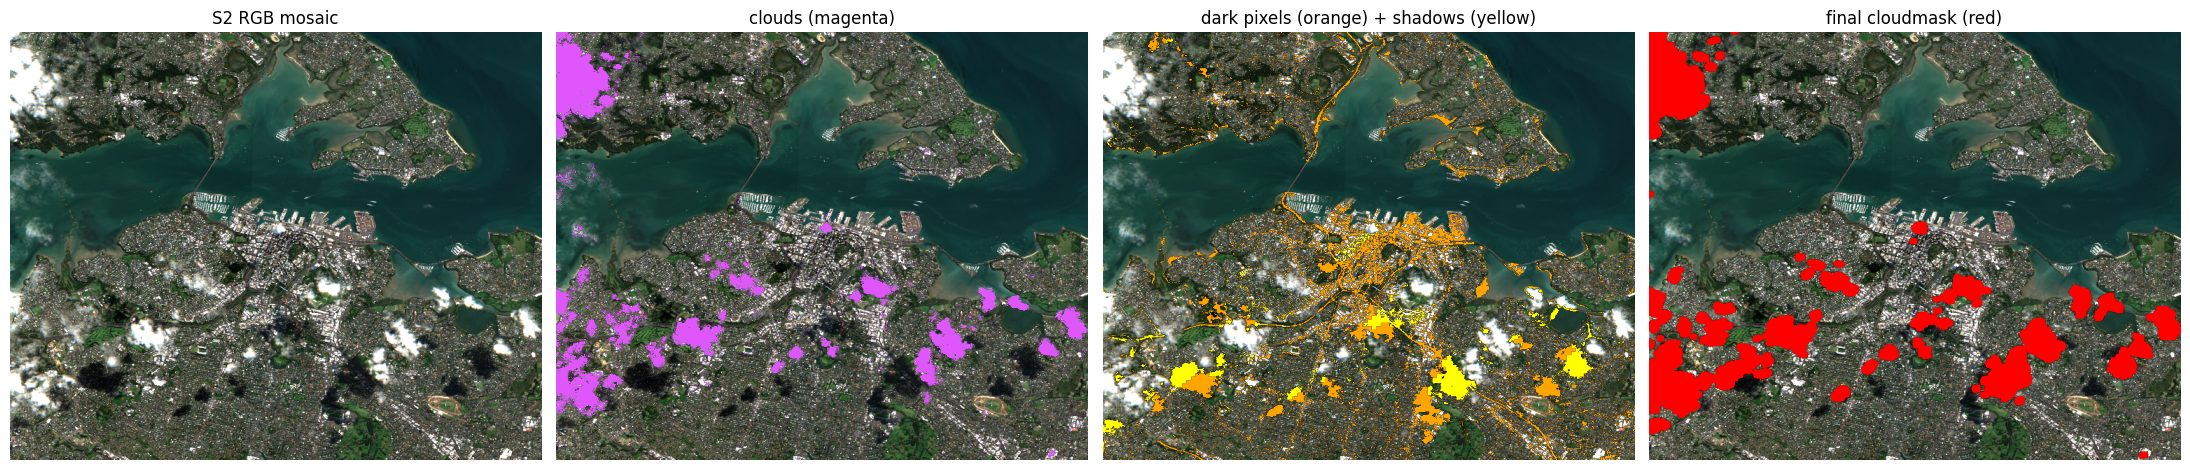

In [12]:
# ---- 报告用图（Q1）：四个组件层分别叠在 RGB 上 ----
mos_eval = s2_sr_cld_col_eval_disp.mosaic()          # 集合镶嵌成一张图
rgb_eval   = ee_thumb(mos_eval, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 2500, 'gamma': 1.1})  # 真彩底图
lay_clouds = ee_thumb(mos_eval.select('clouds').selfMask(), {'palette': ['e056fd']})     # 云：品红
lay_dark   = ee_thumb(mos_eval.select('dark_pixels').selfMask(), {'palette': ['orange']})# 暗像元：橙
lay_shadow = ee_thumb(mos_eval.select('shadows').selfMask(), {'palette': ['yellow']})    # 云影：黄
lay_mask   = ee_thumb(mos_eval.select('cloudmask').selfMask(), {'palette': ['red']})     # 最终掩膜：红

fig, axes = plt.subplots(1, 4, figsize=(22, 6))      # 一行四联图
titles = ['S2 RGB mosaic', 'clouds (magenta)', 'dark pixels (orange) + shadows (yellow)', 'final cloudmask (red)']  # 子图标题
overlays = [[], [lay_clouds], [lay_dark, lay_shadow], [lay_mask]]    # 每个子图要叠加的层
for ax, t, ovs in zip(axes, titles, overlays):       # 逐子图绘制
    ax.imshow(rgb_eval)                              # 铺 RGB 底图
    for ov in ovs:                                   # 依次叠加彩色层（PNG 自带透明通道）
        ax.imshow(ov)                                # 叠加
    ax.set_title(t); ax.axis('off')                  # 标题；关坐标轴
plt.tight_layout()                                   # 收紧布局
plt.savefig(f'{FIGDIR}/fig_q1_layers.png', dpi=110, bbox_inches='tight')     # 存盘（答 Q1 的证据）
plt.show()                                           # 同时显示

Well now! That is considerably better than what we have been using before!

(1) Zoom in to a cloudy region and look at the S2 image, 'clouds' layer, 'dark pixels',  and the 'shadows' layers. Write a short paragraph that discusses:
- The performance of each masking element. Are they perfect or getting confused? What is causing the confusion?
- How do the three elements work together to define pixels that are not clear?
I am looking for you to show an understanding of both the algorithim you have just applied and the underlying spectral sensing principles.

(10 pts)

### ✍️ Answer (1)

The clouds layer from s2cloudless captures the bright cumulus cores very reliably: every dense white cloud visible in the RGB mosaic, over the harbour and over the suburbs, is flagged. It becomes confused at cloud margins and over thin semi transparent cloud, where the pixel probability falls below the 50 percent threshold, so small wispy clouds and the outer halo of larger clouds are missed. The dark pixels layer is by far the noisiest element. It is a simple radiometric threshold, B8 reflectance below 0.15 excluding water, so it fires on everything that is dark at 842 nm: asphalt roads, shaded south facing slopes, dense vegetation and the coastal fringe. On its own it would be useless as a shadow detector. The shadows layer shows why the chain still works: a dark pixel is only accepted as shadow where it also falls inside the cloud projection, computed by dragging every detected cloud along the shadow azimuth of 90 degrees minus the mean solar azimuth for up to CLD_PRJ_DIST km. In my scene the surviving shadow patches sit consistently on the south to south west side of their parent clouds, exactly where a summer sun positioned to the north must cast them, and nearly all of the urban false dark pixels are rejected because no cloud lies up sun of them. The three elements therefore act as independent physical tests that multiply together: a spectral brightness classifier proposes cloud, a NIR darkness test proposes candidate shadows, and solar geometry arbitrates which candidates are physically possible. Their union is then cleaned morphologically, focalMin removes isolated speckle and focalMax dilates by the buffer distance, giving a final cloudmask that covers each cloud together with its displaced shadow.

> 中文速记：云层抓亮云很准、漏薄云；暗像元层在城区满地误报（路面/阴坡/植被 NIR 都暗）；但暗像元 ∩ 太阳几何投影 = 影子，误报几乎全被几何条件否决（影子都在云的南西南侧，太阳在北）。云 ∪ 影 → 去斑 → 膨胀 = 最终掩膜。

(2) Exercise: change the above CLD_PRB_THRESH, NIR_DRK_THRESH, CLD_PRJ_DIST, and BUFFER input variables and rerun the previous cells to see how the results change. Present a figure that compares between the first version you ran and your final version. State the values you have selected and describe the improvements in performance you have managed to achieve in the figure caption.

(10 pts)

**（自加）说明**：Q2 的对比实验放在下面「应用掩膜出合成图」的流程之后（要用到 `apply_cld_shdw_mask`），成果图与答案见那里。

Finally for this section, let's apply this cloud mask to our data and generate a 'cloud free' image. Replace my parameters used below with the ones you have selected based on your answer to question 2.

In [13]:
# Tweaked control variables ｜ 调优后的控制参数（Q2 选定值，替换讲义默认值）
AOI = ee.Geometry.Point(174.7633, -36.8485)          # 兴趣区不变
START_DATE = '2023-01-01'                            # 日期不变
END_DATE = '2023-03-31'                              # 日期不变
CLOUD_FILTER = 60                                    # 场景级过滤不变
CLD_PRB_THRESH = 40                            # 50→40：调低概率阈值，把更多薄云边缘抓进掩膜
NIR_DRK_THRESH = 0.18                            # 0.15→0.18：调高暗像元阈值，把偏亮的半影也算进候选影
CLD_PRJ_DIST = 2                              # 1→2：投影距离加倍，接住离云更远的影子
BUFFER = 60                                    # 50→60：缓冲加宽，盖住云边半透明的光环

# Re-collect the S2 as we have changed our filtering params ｜ 参数变了，重新取集合
s2_sr_cld_col = get_s2_sr_cld_col(AOI, START_DATE, END_DATE)         # 用新参数重建配对集合

In [14]:
# Define a function to apply the cloud mask to the S2 spectral bands ｜ 把掩膜真正应用到光谱波段上
def apply_cld_shdw_mask(img):
    cloudmask = img.select('cloudmask')              # 取出最终掩膜波段
    # Mask cloudy pixels ｜ 掩掉云/影像元（掩膜取反：保留掩膜=0 的干净像元）
    masked_img = img.updateMask(cloudmask.Not())     # 云影处变为无数据
    # Keep cloudmask and probability bands ｜ 但掩膜和概率这两个波段本身要保留完整（后面聚类要用）
    cloudmask_band = img.select('cloudmask')         # 原始掩膜波段（未被抠）
    probability_band = img.select('probability')     # 原始概率波段（未被抠）
    masked_img = masked_img.addBands([cloudmask_band, probability_band], overwrite=True)  # 盖回这两个波段
    return masked_img                                # 返回抠掉云影的影像

In [15]:
# Process the collection ｜ 走完整条流水线：加掩膜 → 应用掩膜 → 中值合成
s2_sr_median = (s2_sr_cld_col.map(add_cld_shdw_mask)                 # 每景算掩膜
                             .map(apply_cld_shdw_mask)               # 每景抠掉云影
                             .median())                              # 逐像元取时间中值 → 无云合成图

In [16]:
# Display the cloud free composite ｜ 显示无云合成图
def display_cloud_free_mosaic(s2_sr_median, AOI):
    # Create a geemap Map object and center it on the AOI ｜ 建图并定位
    m = geemap.Map()                                 # 新地图
    m.centerObject(AOI, 12)                          # 定位兴趣区

    # Add the Sentinel-2 RGB mosaic ｜ 加真彩图层
    m.addLayer(
        s2_sr_median,                                # 无云合成图
        {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 2500, 'gamma': 1.1},      # 真彩参数
        'S2 cloud-free mosaic')                      # 图层名

    return m                                         # 返回地图

display_map = display_cloud_free_mosaic(s2_sr_median, AOI)           # 生成地图
display_map                                          # 显示

Map(center=[-36.84850000000001, 174.7633], controls=(WidgetControl(options=['position', 'transparent_bg'], pos…

**（自加）Q2 对比实验**：把 baseline 参数和最终参数各跑一遍完整管线。出图有两个讲究：① 范围选西南 Waitakere 森林和西北城乡结合部这两个 baseline 有残云/薄雾的区域放大看；② 用 `unmask(0)` 把合成图里的无数据空洞渲染成黑色——否则空洞和云都是白的根本分不开（踩过）。同时统计整个大范围的被掩比例与空洞率。

baseline: masked 44.6% of observations, composite gaps 0.48%
tuned   : masked 50.8% of observations, composite gaps 1.28%


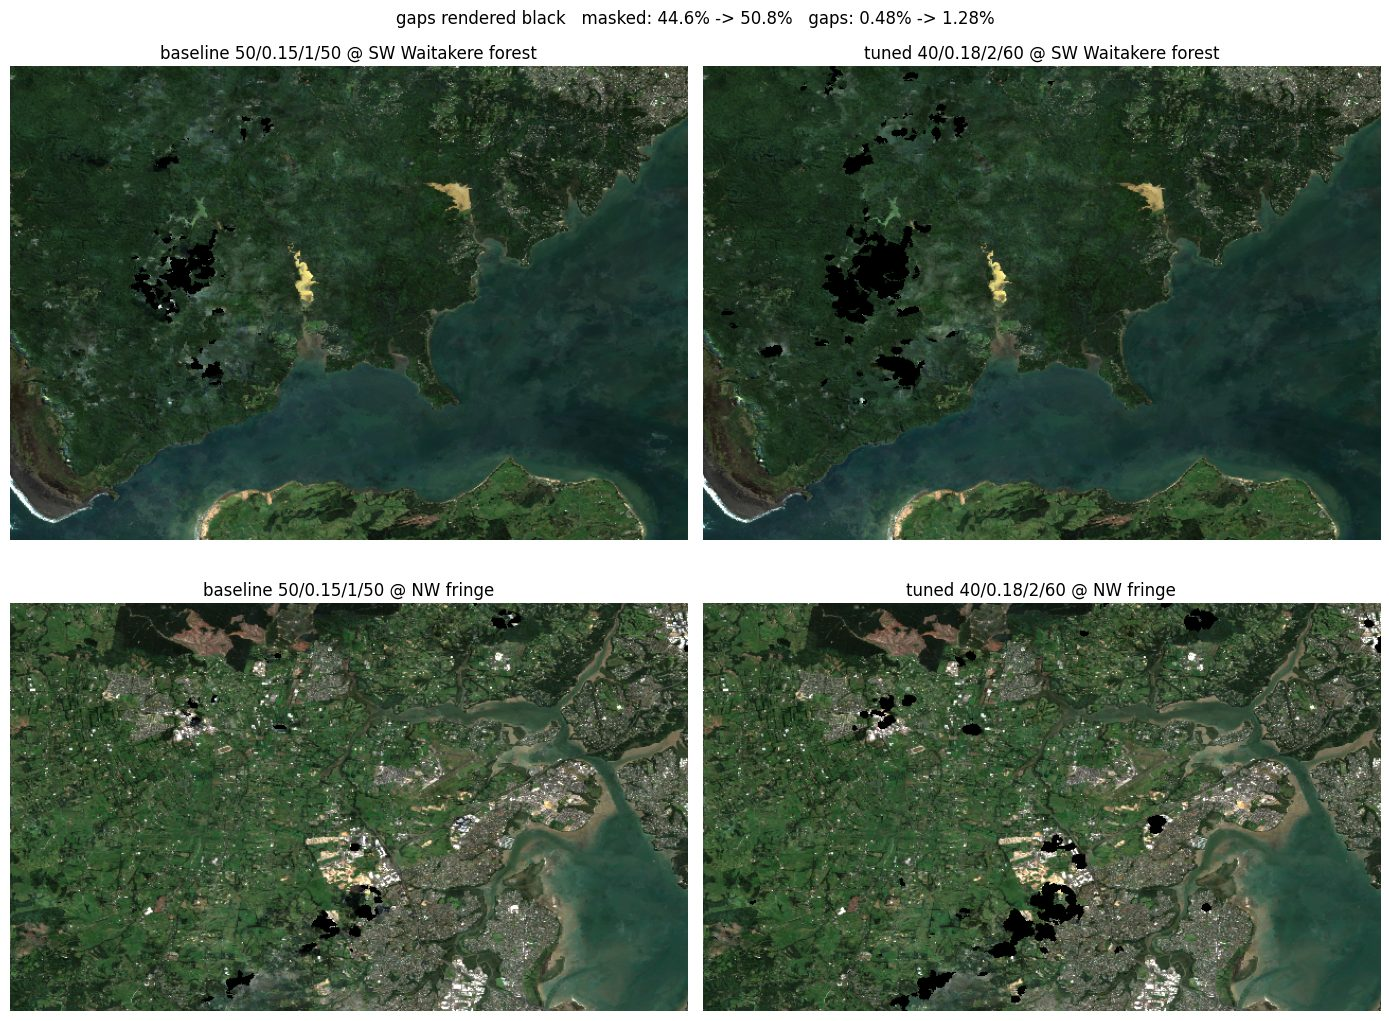

In [17]:
# ---- Q2 对比实验：baseline 参数 vs 调优参数 ----
REGION_W = ee.Geometry.Rectangle([174.45, -37.05, 174.95, -36.72])   # 统计用大范围：装进西南森林
REG_A = ee.Geometry.Rectangle([174.48, -37.06, 174.68, -36.92])      # 放大区 A：西南 Waitakere 森林（baseline 残云区）
REG_B = ee.Geometry.Rectangle([174.50, -36.86, 174.70, -36.74])      # 放大区 B：西北城乡结合部（baseline 薄雾区）

def build_composite(p, n, d, b):                     # 用一组参数走完整条管线，返回合成图和两个统计量
    global CLD_PRB_THRESH, NIR_DRK_THRESH, CLD_PRJ_DIST, BUFFER      # 管线函数读全局参数，这里统一改写
    CLD_PRB_THRESH, NIR_DRK_THRESH, CLD_PRJ_DIST, BUFFER = p, n, d, b            # 设定本组参数
    col = get_s2_sr_cld_col(AOI, START_DATE, END_DATE).map(add_cld_shdw_mask)    # 重建集合并逐景加掩膜波段
    med = col.map(apply_cld_shdw_mask).median()      # 应用掩膜后取中值合成
    frac = col.map(lambda i: i.select('cloudmask')).mean().reduceRegion(         # 集合平均被掩比例
        ee.Reducer.mean(), REGION_W, 120).get('cloudmask').getInfo()             # 大范围 120m 统计
    gap = ee.Image(1).subtract(med.select('B4').mask()).reduceRegion(            # 合成图无数据空洞率
        ee.Reducer.mean(), REGION_W, 120).get('constant').getInfo()              # 同样 120m 统计
    return med, frac, gap                            # 返回三件套

med_base, frac_base, gap_base = build_composite(50, 0.15, 1, 50)     # 讲义 baseline 参数
med_tune, frac_tune, gap_tune = build_composite(40, 0.18, 2, 60)      # 我的最终参数（此后全局保持这组）
print(f'baseline: masked {frac_base:.1%} of observations, composite gaps {gap_base:.2%}')  # baseline 统计
print(f'tuned   : masked {frac_tune:.1%} of observations, composite gaps {gap_tune:.2%}')  # 调优后统计

VIS_RGB = {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 2500, 'gamma': 1.1}   # 真彩参数
def thumb_gapblack(med, reg):                        # 出小图：空洞 unmask 成 0 → 渲染成黑色（与白云区分开）
    return ee_thumb(med.unmask(0), VIS_RGB, region=reg, dim=640)     # 渲染

fig, axes = plt.subplots(2, 2, figsize=(14, 11))     # 2×2：行=区域，列=参数版本
panels = [(REG_A, 'SW Waitakere forest'), (REG_B, 'NW fringe')]      # 两个放大区
for j, (reg, rn) in enumerate(panels):               # 逐区域
    for i, (med, mn, fr) in enumerate([(med_base, 'baseline 50/0.15/1/50', frac_base),           # 左列 baseline
                                        (med_tune, 'tuned 40/0.18/2/60', frac_tune)]):    # 右列 tuned
        axes[j][i].imshow(thumb_gapblack(med, reg))  # 画图（黑=空洞）
        axes[j][i].set_title(f'{mn} @ {rn}')     # 标题
        axes[j][i].axis('off')                       # 关轴
plt.suptitle(f'gaps rendered black   masked: {frac_base:.1%} -> {frac_tune:.1%}   gaps: {gap_base:.2%} -> {gap_tune:.2%}')   # 总标题带统计
plt.tight_layout()                                   # 收紧
plt.savefig(f'{FIGDIR}/fig_q2_compare.png', dpi=110, bbox_inches='tight')      # 存盘（Q2 成果图）
plt.show()                                           # 显示

__ANSWER2_PLACEHOLDER__

Now THAT is a cloud-free image! (Well, with my thresholds we still have a little there over the SW forest, can yours do better?).

(3) This process has managed to avoid masking out the many bright white roofs of Auckland as cloud, despite them appearing very similar to cloud in the RGB visualization. How has the algorithm achieved this?
(5 pts)


________________________________________________________________________________

### ✍️ Answer (3)

The separation is not made in RGB space at all. s2cloudless is a gradient boosting classifier trained on a very large set of labelled Sentinel 2 scenes and it sees the full spectral vector of each pixel, not just the three visible bands in which a white roof and a cloud look identical. Outside the visible the two materials diverge. A roof sits at the bottom of the full atmospheric column, so in band B9 at 945 nm its signal is strongly attenuated by column water vapour, while a cloud top rides above much of that vapour and stays bright. Cloud droplets also scatter strongly and smoothly right across the VNIR and show a characteristic droplet size signature in the SWIR, whereas roof materials have flatter, drier spectra. The classifier therefore assigns roofs a low cloud probability and the 50 percent threshold never fires on them. Two further details help: the focalMin erosion step removes any residual single pixel false positives, which is the scale at which roofs would appear, and a roof can never be corroborated through the shadow branch because there is no matching dark patch displaced along the solar azimuth at cloud height.

> 中文速记：白屋顶只在可见光里像云。B9 水汽带：屋顶在大气柱底被吸收、云顶在水汽之上仍亮；SWIR 液滴散射特征屋顶也没有。s2cloudless 用全波段 ML 分类而非 RGB 阈值，再加 focalMin 去小斑、屋顶配不出对应方向的影子。

# Extending S2 Cloudless with a clustering approach
The process we explored in the prior section has worked really rather well! But you saw in the exercise that it does rely on you setting the local paramaters. This is a manual process and one that is at risk of reduced effectiveness if we are clearing cloud over a wide area. This is particularly the case for cirrus and other thin clouds (e.g. cloud edges) that the thresholds are very sensitive to.

Therefore, let us extend our cloud-clearing algorithim into one that includes a clustering-step in which we sample the pixels around the edge of our clouds and test if they should be clustered into our cloud mask.

We will now implement the following workflow:
1.   Reset our data stack, with somewhat worse settings than the very good ones we have just set, in order to make this a better (for humans) teaching exercise.
2.   Define what counts as inside a cloud, outside a cloud and the edge of a cloud.
3.   Vizualize these samples and determine if we can perform meaningful clustering on them.
4.   Perform clustering of the border zone pixels with either the clouds or the cloud free.





In [18]:
# First, lets make our cloud clearing 'worse' in order to more clearly demonstrate our clustering alg
# ｜ 故意把参数调"差"，留下更多没掩到的云，好让聚类法有活干（教学需要）
# Tweaked control variables ｜ 较差的控制参数
AOI = ee.Geometry.Point(174.7633, -36.8485)          # 兴趣区不变
START_DATE = '2023-01-01'                            # 日期不变
END_DATE = '2023-03-31'                              # 日期不变
CLOUD_FILTER = 30                                    # 60→30：只要相对干净的场景（数量变少）
CLD_PRB_THRESH = 30                                  # 50→30：阈值调低（连薄雾都算云，掩膜更碎）
NIR_DRK_THRESH = 0.15                                # 不变
CLD_PRJ_DIST = 1                                     # 不变
BUFFER = 5                                           # 50→5：几乎不做缓冲（云边留下大量漏网像元）

# Re-collect the S2 as we have changed our filtering params ｜ 参数变了重新取集合
s2_sr_cld_col = get_s2_sr_cld_col(AOI, START_DATE, END_DATE)         # 重建集合

# Re-run s2cloudless approach, this time with .moasic as the compositing operator
# ｜ 这次用 mosaic（取最上层）而不是 median 合成，保住我们要用的掩膜图层
s2_sr_mosaic = (s2_sr_cld_col.map(add_cld_shdw_mask)                 # 每景算掩膜
                             .map(apply_cld_shdw_mask)               # 每景抠云影
                             .mosaic())              # ← 换成 mosaic：便于 k-means 工作流使用掩膜层

In [19]:
def define_cloud_zones(img, edge_buffer=120):
    cloudmask = img.select('cloudmask')              # 取掩膜波段

    # Interior cloud pixels: cloudmask==1, away from edges (small erosion)
    # ｜ 云内部：掩膜=1 再向内腐蚀 3 像素（离云边远一点，标签更纯）
    cloud_interior = cloudmask.selfMask().focal_min(3)               # 腐蚀后的云核心

    # Interior clear pixels: cloudmask==0, away from edges (medium erosion)
    # ｜ 晴空内部：掩膜=0 再向内腐蚀 10 像素
    clear_interior = cloudmask.Not().selfMask().focal_min(10)        # 腐蚀后的晴空核心

    # Cloud edge pixels: buffer zone around clouds, but outside cloudmask
    # ｜ 云边缘：云向外膨胀出的环带，且不属于云本体（真正模糊地带）
    cloud_edge = cloudmask.focal_max(edge_buffer / 10).And(cloudmask.Not())      # 外扩环 ∩ 非云

    return cloud_interior, clear_interior, cloud_edge                # 返回三个区带掩膜

In [20]:
def sample_zones(img, AOI, edge_buffer=20):
    cloudmask = img.select('cloudmask')              # 取掩膜波段

    cloud_interior = cloudmask.selfMask()            # 云区带：掩膜=1
    clear_interior = cloudmask.Not().selfMask()      # 晴区带：掩膜=0
    cloud_edge = cloudmask.focal_max(edge_buffer).And(cloudmask.Not())           # 边缘带：云外扩 20 像素减云本体

    sample_bands = ['B2', 'B3', 'B4', 'B5', 'B6' , 'B9', 'B8', 'B11', 'B12']    # 参与采样的光谱波段
    if 'probability' in img.bandNames().getInfo():   # 如果影像里带云概率波段
        sample_bands.append('probability')           # 一并采出来（画直方图用）

    img_for_sampling = img.select(sample_bands)      # 只留采样波段

    cloud_samples = img_for_sampling.updateMask(cloud_interior).sample(          # 云区带随机采样
        region=AOI.buffer(2000), scale=10, numPixels=5000, seed=0, geometries=True)          # 市中心 2km 内，10m 尺度，带坐标
    clear_samples = img_for_sampling.updateMask(clear_interior).sample(          # 晴区带随机采样
        region=AOI.buffer(2000), scale=10, numPixels=5000, seed=1, geometries=True)          # 换个种子
    edge_samples = img_for_sampling.updateMask(cloud_edge).sample(               # 边缘带随机采样
        region=AOI.buffer(2000), scale=10, numPixels=5000, seed=2, geometries=True)          # 再换个种子

    return cloud_samples, clear_samples, edge_samples                # 返回三组样本

In [21]:
# Gather our samples ｜ 执行采样
cloud_samples, clear_samples, edge_samples = sample_zones(s2_sr_mosaic, AOI)     # 三个区带各采一批

# Function to convert a earth engine feature class to a pandas df ｜ 把 EE 要素集拉到本地转 DataFrame
def fc_to_df(fc):
    features = fc.getInfo()['features']              # 一次性把全部要素拉到本地（getInfo）
    rows = []                                        # 收集行
    for f in features:                               # 逐要素
        props = f['properties']                      # 属性（各波段值）
        coords = f['geometry']['coordinates']        # 点坐标
        props['longitude'] = coords[0]               # 经度加进属性
        props['latitude'] = coords[1]                # 纬度加进属性
        rows.append(props)                           # 收进列表
    return pd.DataFrame(rows)                        # 转成表


# Carry out the conversion and sanity print out what we have ｜ 转换并打印数量做体检
cloud_df = fc_to_df(cloud_samples)                   # 云样本表
clear_df = fc_to_df(clear_samples)                   # 晴样本表
edge_df = fc_to_df(edge_samples)                     # 边缘样本表

print(f"Cloud samples: {len(cloud_df)}")             # 云样本数
print(f"Clear samples: {len(clear_df)}")             # 晴样本数
print(f"Edge samples: {len(edge_df)}")               # 边缘样本数
print("Cloud columns:", cloud_df.columns)            # 列名（各波段+坐标）

Cloud samples: 727
Clear samples: 4310
Edge samples: 1930
Cloud columns: Index(['B11', 'B12', 'B2', 'B3', 'B4', 'B5', 'B6', 'B8', 'B9', 'probability',
       'longitude', 'latitude'],
      dtype='str')


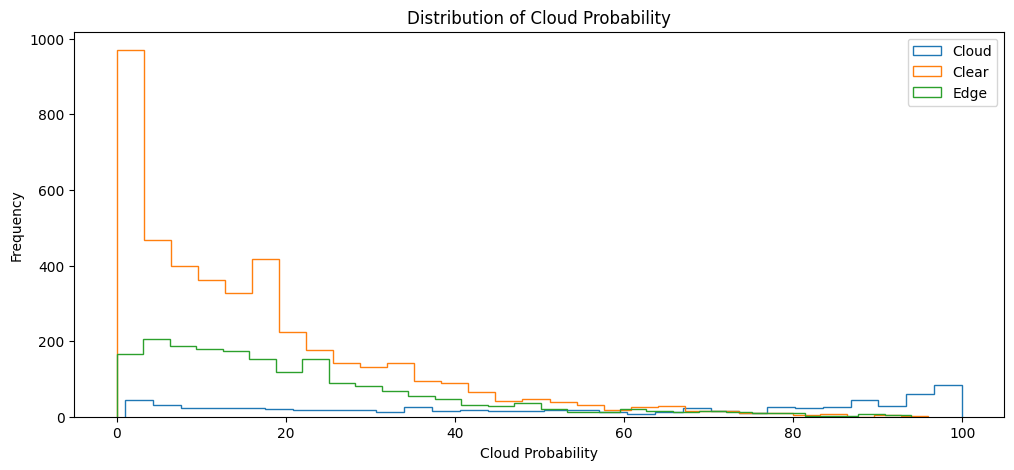

In [22]:
# Histogram of cloud probability by class ｜ 三类样本的云概率直方图
plt.figure(figsize=(12, 5))                          # 建图
plt.hist(cloud_df['probability'], bins=30, histtype='step', label='Cloud')       # 云类概率分布
plt.hist(clear_df['probability'], bins=30, histtype='step', label='Clear')       # 晴类概率分布
plt.hist(edge_df['probability'], bins=30, histtype='step', label='Edge')         # 边缘类概率分布
plt.xlabel('Cloud Probability')                      # x 轴：云概率
plt.ylabel('Frequency')                              # y 轴：频数
plt.legend()                                         # 图例
plt.title('Distribution of Cloud Probability')       # 标题
plt.savefig(f'{FIGDIR}/fig_q4_hist.png', dpi=110, bbox_inches='tight')           # 存盘（Q4 证据）
plt.show()                                           # 显示

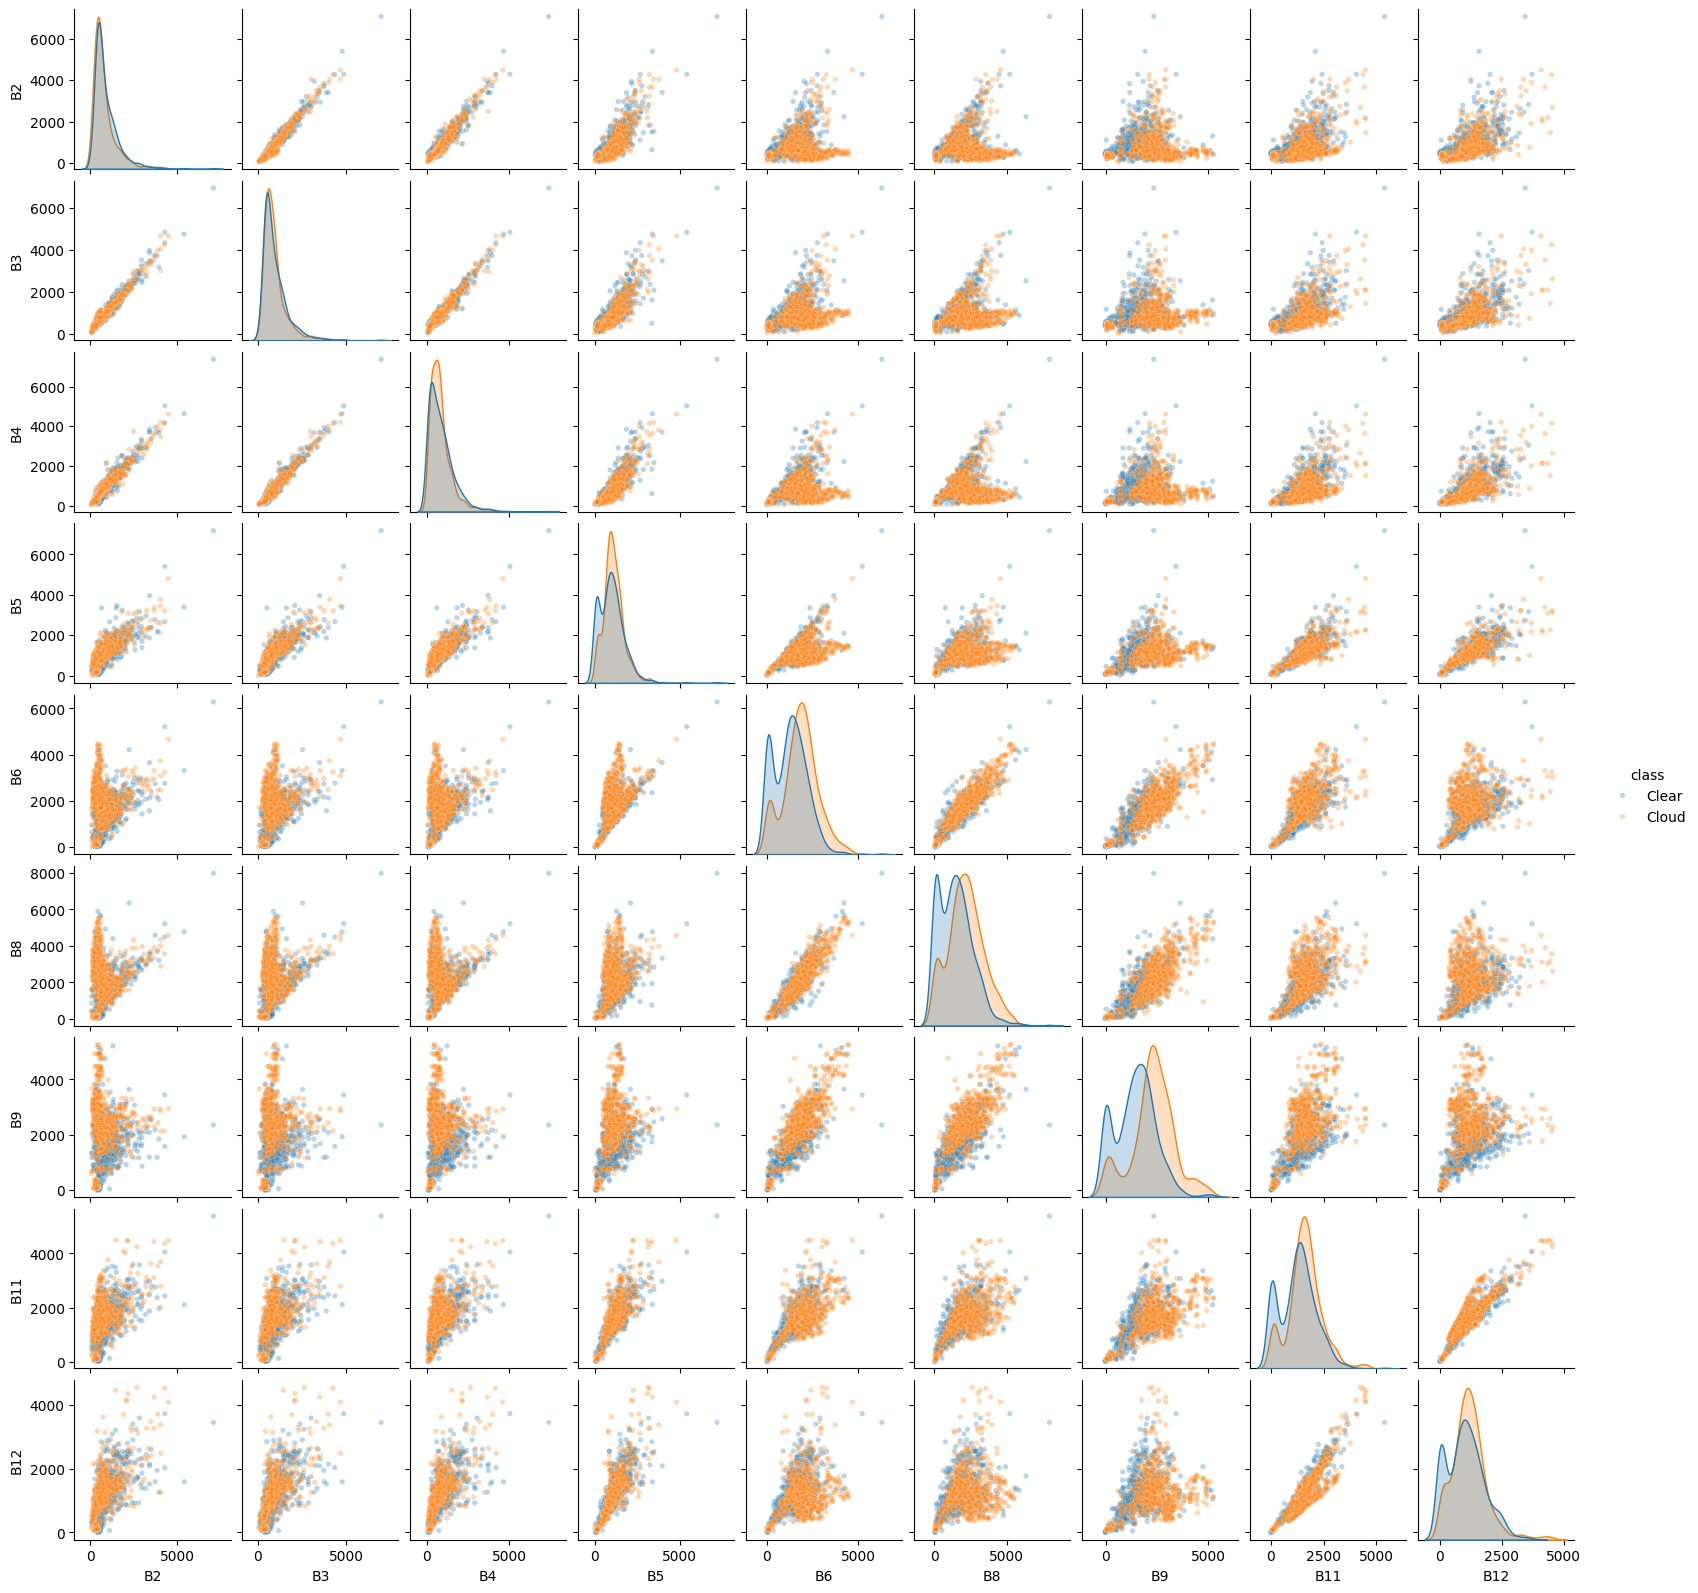

In [23]:
# Plot out all the bands, by the two 'labelled' classes that we want to discriminate between
# ｜ 画出全部波段的两两配对图，看云/晴两类在每个波段平面里能不能分开
# Add class labels ｜ 打上类别标签
cloud_df['class'] = 'Cloud'                          # 云类
clear_df['class'] = 'Clear'                          # 晴类

# Combine to one df ｜ 合并成一张表
combined_df = pd.concat([cloud_df, clear_df])        # 纵向拼接

# We will carry out somne class balancing here ｜ 做类平衡（两类数量差很多）
# Find smallest class count ｜ 找出较少那类的数量
min_count = combined_df['class'].value_counts().min()                # 少数类样本数

# Downsample each class to min_count ｜ 每类都下采样到该数量
balanced_df = combined_df.groupby('class').sample(n=min_count, random_state=42)  # 平衡后的表

# Now plot with balanced_df ｜ 用平衡后的数据画配对图
# This is going to make a big plot that you will have to scroll around! Pay particular attention to the histogram plots on the diagonal.
# ｜ 图很大要滚动看；重点看对角线上的直方图（单波段可分性）
bands = ['B2', 'B3', 'B4', 'B5', 'B6' , 'B8', 'B9', 'B11', 'B12']   # 参与配对的波段
sns.pairplot(balanced_df, vars=bands, hue='class', plot_kws={'alpha':0.3, 's':15}, height=1.8)   # 9×9 配对图（height 调小控制体积）
plt.savefig(f'{FIGDIR}/fig_q4_pairplot.png', dpi=80, bbox_inches='tight')        # 存盘（Q4 证据）
plt.show()                                           # 显示

(4) What do the histograms of cloud detection probability (as judged by s2cloudless) plotted in the three classes we have set here, AND the pair plot of all bands available tell us about our ability to tell cloudy vs non-cloud pixels apart? Make sure to explain your answer with reference to physical principles and the statistical foundations of ML (5 pts)

(5) Which bands are therefore going to be the best to use in our K-means clustering approach and why? (5 pts)

With our choices made, let us now test if we can implement k-means as a tool by which to assign those edge pixels into either the cloudy or clear classes. Noting that I have placed default band choices in the 'features to use for clustering' line. You do not need to use just three bands.

Run this section first with the default bands, and then change it to the ones you have selected in question 5. Observe the difference it makes...

**（自加）Q4/Q5 证据**：光看配对图太主观，这里逐波段算云/晴两类的标准化均值差（Cohen’s d），直接量化每个波段的可分性并排序。

In [24]:
# ---- Q4/Q5 证据：逐波段算云/晴可分性（Cohen's d 标准化均值差）----
BANDS9 = ['B2', 'B3', 'B4', 'B5', 'B6', 'B8', 'B9', 'B11', 'B12']   # 全部 9 个光谱波段
rows = []                                            # 收集统计
for b in BANDS9:                                     # 逐波段
    m_cloud = cloud_df[b].mean()                     # 云类均值
    m_clear = clear_df[b].mean()                     # 晴类均值
    s_pool = np.sqrt((cloud_df[b].var() + clear_df[b].var()) / 2)    # 合并标准差
    rows.append((b, abs(m_cloud - m_clear) / s_pool, m_cloud, m_clear))          # d = 均值差 / 合并标准差
rank_df = pd.DataFrame(rows, columns=['band', 'cohen_d', 'cloud_mean', 'clear_mean'])            # 转表
rank_df = rank_df.sort_values('cohen_d', ascending=False).reset_index(drop=True) # 按可分性降序排
print(rank_df.round(2))                              # 打印排名表
BEST_BANDS = list(rank_df['band'].head(4))           # 取可分性最高的 4 个波段，供 Q5 使用
print('Selected bands for k-means:', BEST_BANDS)     # 明示选择结果

  band  cohen_d  cloud_mean  clear_mean
0   B9     0.87     2297.56     1425.07
1   B6     0.64     1833.64     1250.32
2   B8     0.63     2174.18     1436.19
3  B11     0.44     1596.73     1240.11
4  B12     0.21     1198.72     1039.70
5   B5     0.17     1107.44      990.92
6   B2     0.15      792.82      898.81
7   B3     0.06      930.31      968.08
8   B4     0.05      832.53      871.77
Selected bands for k-means: ['B9', 'B6', 'B8', 'B11']


__ANSWER4_PLACEHOLDER__

__ANSWER5_PLACEHOLDER__

In [25]:
# Use the balanced_df from before for cloud and clear pixels only ｜ 训练集：平衡后的云+晴样本
train_df = balanced_df[balanced_df['class'].isin(['Cloud', 'Clear'])]            # 只留这两类

# Features to use for clustering ｜ 聚类特征（讲义默认：可见光三波段，先按默认跑）
features = ['B2', 'B3', 'B4']                        # 默认特征（之后按 Q5 结论换成 BEST_BANDS 对比）

# Prepare training data (cloud=1, clear=0) ｜ 准备训练数据
X_train = train_df[features].values                  # 特征矩阵
y_train = (train_df['class'] == 'Cloud').astype(int).values          # 真标签：云=1 晴=0（只用来解释簇，不参与聚类）

# Fit k-means with 2 clusters on training data ｜ 无监督聚成两簇
kmeans = KMeans(n_clusters=2, random_state=42).fit(X_train)          # 训练 k-means

# Map clusters to classes by majority vote on training data ｜ 用多数票把簇号翻译成类别
labels, counts = np.unique(kmeans.labels_[y_train==0], return_counts=True)       # 晴样本落各簇的数量
clear_cluster = labels[np.argmax(counts)]            # 晴类对应的簇号
labels, counts = np.unique(kmeans.labels_[y_train==1], return_counts=True)       # 云样本落各簇的数量
cloud_cluster = labels[np.argmax(counts)]            # 云类对应的簇号

# Prepare edge pixels data for prediction ｜ 边缘像元特征
edge_features = edge_df[features].values             # 边缘样本的特征矩阵

# Predict clusters for edge pixels ｜ 给边缘像元预测簇
edge_clusters = kmeans.predict(edge_features)        # 每个边缘像元离哪个簇中心近

# Assign class labels to edge pixels based on cluster ｜ 簇号翻译回类别名
edge_df['predicted_class'] = ['Cloud' if c == cloud_cluster else 'Clear' for c in edge_clusters] # 写回表

# Quick summary ｜ 快速汇总
print(edge_df['predicted_class'].value_counts())     # 两类边缘像元数量

predicted_class
Cloud    1512
Clear     418
Name: count, dtype: int64


And now plot up the results of this below. Play around with this plotting and take a look at each set of band combinations you have chosen. Think about where the boundary is being placed, does it make sense?

predicted_class
Cloud    1512
Clear     418
Name: count, dtype: int64


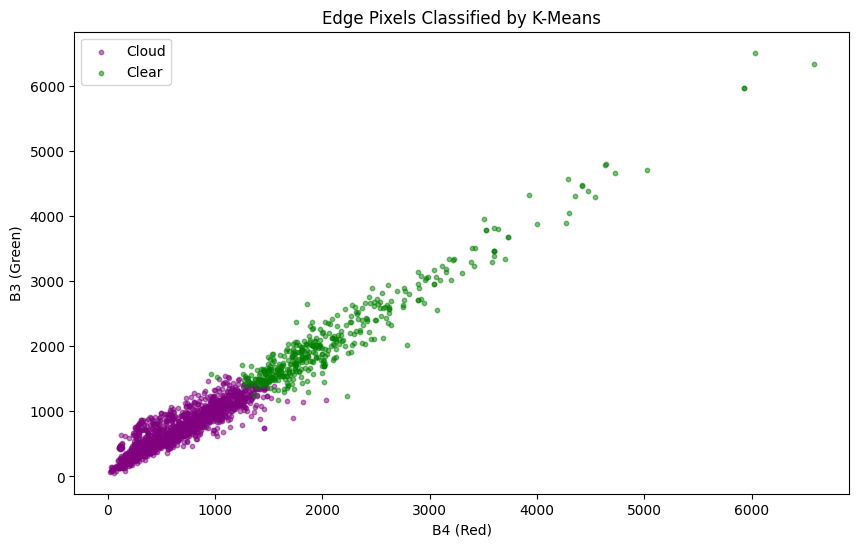

In [26]:
# Count of predicted classes ｜ 预测类别计数
counts = edge_df['predicted_class'].value_counts()   # 统计
print(counts)                                        # 打印

# Scatter plot of edge pixels B4 vs B3 colored by predicted class ### CHANGE THIS TO YOUR OTHER BANDS ###
# ｜ 边缘像元散点图（默认 B4-B3 平面；讲义提示可换成自己选的波段）
plt.figure(figsize=(10, 6))                          # 建图
for label, color in zip(['Cloud', 'Clear'], ['purple', 'green']):    # 两类各一种颜色
    subset = edge_df[edge_df['predicted_class'] == label]            # 取该类
    plt.scatter(subset['B4'], subset['B3'], label=label, alpha=0.5, s=10, c=color)               # 画散点

plt.xlabel('B4 (Red)')                               # x 轴
plt.ylabel('B3 (Green)')                             # y 轴
plt.title('Edge Pixels Classified by K-Means')       # 标题
plt.legend()                                         # 图例
plt.savefig(f'{FIGDIR}/fig_q5_default_scatter.png', dpi=110, bbox_inches='tight')                # 存盘
plt.show()                                           # 显示

**（自加）Q5 对比**：按讲义要求，把特征从默认 B2/B3/B4 换成上面选出的最佳波段重新聚类，量化对比两版的簇纯度与边缘分类结果。

default B2/B3/B4     : purity=51.8%, edge->Cloud 78.3%
best ['B9', 'B6', 'B8', 'B11']: purity=64.9%, edge->Cloud 58.8%


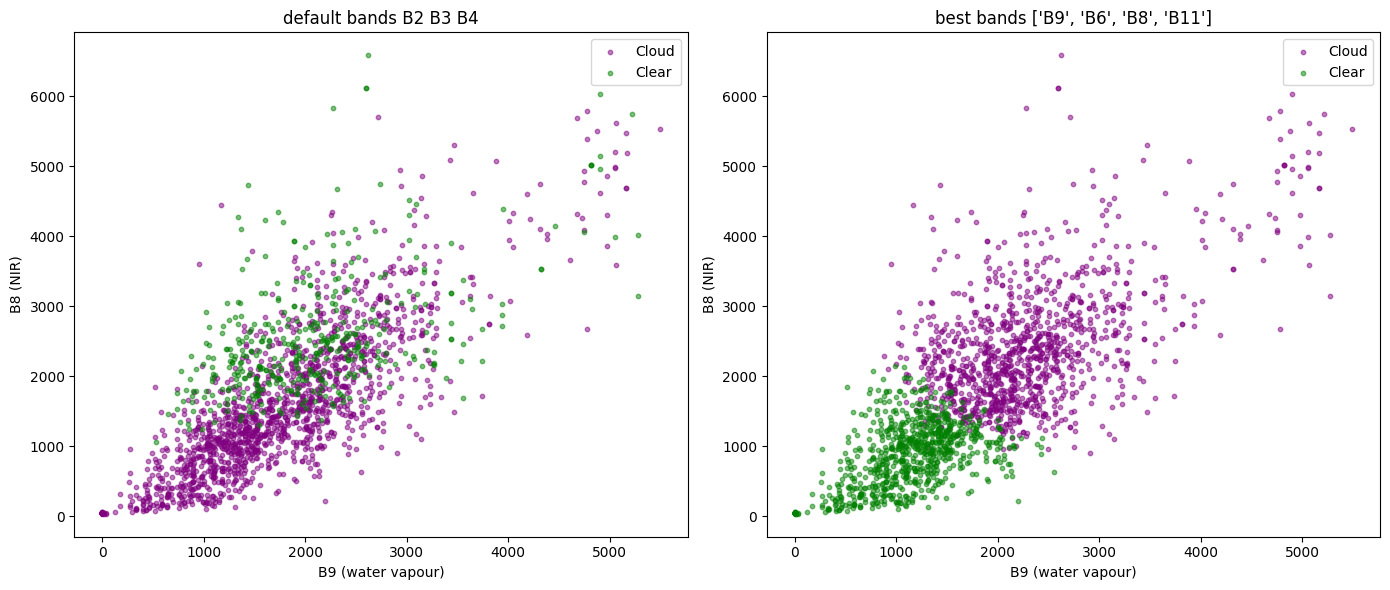

In [27]:
# ---- Q5 对比：默认波段 vs 最佳波段 ----
def kmeans_on(feats):                                # 用给定特征列训练 k-means 并给边缘像元分类
    X = train_df[feats].values                       # 训练特征
    y = (train_df['class'] == 'Cloud').astype(int).values            # 真标签（只用于解释簇）
    km = KMeans(n_clusters=2, random_state=42).fit(X)                # 聚类
    lab, cnt = np.unique(km.labels_[y == 1], return_counts=True)     # 云样本的簇分布
    cloud_c = lab[np.argmax(cnt)]                    # 云簇号
    purity = ((km.labels_ == cloud_c).astype(int) == y).mean()       # 簇-类映射在训练集上的纯度
    pred = km.predict(edge_df[feats].values)         # 边缘像元预测
    edge_cls = np.where(pred == cloud_c, 'Cloud', 'Clear')           # 翻译成类别名
    return purity, edge_cls                          # 返回纯度和边缘分类

pur_def, edge_cls_def = kmeans_on(['B2', 'B3', 'B4'])                # 默认可见光三波段
pur_best, edge_cls_best = kmeans_on(BEST_BANDS)      # Q5 选出的最佳波段
edge_df['predicted_class'] = edge_cls_best           # 用最佳版结果覆盖，供后面 EE 回写用
print(f"default B2/B3/B4     : purity={pur_def:.1%}, edge->Cloud {(edge_cls_def=='Cloud').mean():.1%}")      # 默认版表现
print(f"best {BEST_BANDS}: purity={pur_best:.1%}, edge->Cloud {(edge_cls_best=='Cloud').mean():.1%}")        # 最佳版表现

fig, axes = plt.subplots(1, 2, figsize=(14, 6))      # 并排两图
for ax, cls, ttl in [(axes[0], edge_cls_def, 'default bands B2 B3 B4'),          # 左：默认
                     (axes[1], edge_cls_best, f'best bands {BEST_BANDS}')]:      # 右：最佳
    for label, color in zip(['Cloud', 'Clear'], ['purple', 'green']):            # 两类颜色
        sub = edge_df[cls == label]                  # 该类子集
        ax.scatter(sub['B9'], sub['B8'], label=label, alpha=0.5, s=10, c=color)  # 在 B9-B8 平面看分界
    ax.set_xlabel('B9 (water vapour)'); ax.set_ylabel('B8 (NIR)')    # 轴标签
    ax.set_title(ttl); ax.legend()                   # 标题图例
plt.tight_layout()                                   # 收紧
plt.savefig(f'{FIGDIR}/fig_q5_compare.png', dpi=110, bbox_inches='tight')        # 存盘
plt.show()                                           # 显示

Finally, we will map this back onto earth engine via the following workflow:
1.  Export the classified edge pixels back to Earth Engine as a FeatureCollection
2. Rasterize the classified edge points into an image layer
3. Visualize refined cloud mask in Earth Engine (geemap):

Export to Earth Engine FC:

In [28]:
# Function to go the other way! This time from a dataframe to the feature collection
# ｜ 反向转换：本地 DataFrame → EE FeatureCollection（把分类结果送回云端）
def df_to_ee_fc(df):
    features = []                                    # 收集要素
    for _, row in df.iterrows():                     # 逐行
        geom = ee.Geometry.Point([row['longitude'], row['latitude']])            # 经纬度转点几何
        props = {k: float(row[k]) for k in ['B2', 'B3', 'B4', 'B8', 'probability']}              # 带上几个波段值
        props['predicted_class'] = row['predicted_class']            # 带上预测类别
        features.append(ee.Feature(geom, props))     # 组装要素
    return ee.FeatureCollection(features)            # 打包成要素集

edge_fc = df_to_ee_fc(edge_df)                       # 边缘像元分类结果送回 EE

Rasterize into image layer:

In [29]:
# Map predicted class to numeric ｜ 类别名转数字（栅格化需要数值）
def class_to_numeric(feature):
    cls = feature.get('predicted_class')             # 取类别名
    return feature.set('cloud_refined', ee.Number(ee.Algorithms.If(ee.String(cls).equals('Cloud'), 1, 0)))   # Cloud→1 其他→0

edge_fc_num = edge_fc.map(class_to_numeric)          # 给全部要素加数值属性

# Rasterize: paint 'cloud_refined' on a blank image ｜ 栅格化：把点的数值画到影像上
refined_cloud_mask = edge_fc_num.reduceToImage(      # 点集 → 栅格
    properties=['cloud_refined'],                    # 用哪个属性作像元值
    reducer=ee.Reducer.first())                      # 重叠时取第一个

# Optionally, you can combine this refined mask with your existing cloudmask for a final refined mask
# ｜ 可选：把精修结果与原掩膜取并集，得到最终精修掩膜
final_mask = s2_sr_median.select('cloudmask').max(refined_cloud_mask).rename('cloudmask_refined')            # 逐像元取最大值=并集

Visualize it:

In [30]:
Map = geemap.Map()                                   # 建交互地图
Map.centerObject(AOI, 12)                            # 定位兴趣区

# Show original cloudmask ｜ 显示原始掩膜
Map.addLayer(s2_sr_median.select('cloudmask'), {'palette': ['white', 'red']}, 'Original cloudmask')          # 白→红渐变

# Show refined cloudmask ｜ 显示精修掩膜（k-means 新增的云点）
Map.addLayer(final_mask.selfMask(), {'palette': ['blue']}, 'Refined cloudmask')  # 蓝色散点

Map                                                  # 显示

Map(center=[-36.84850000000001, 174.7633], controls=(WidgetControl(options=['position', 'transparent_bg'], pos…

**（自加）静态版**：上面交互图的静态存档。

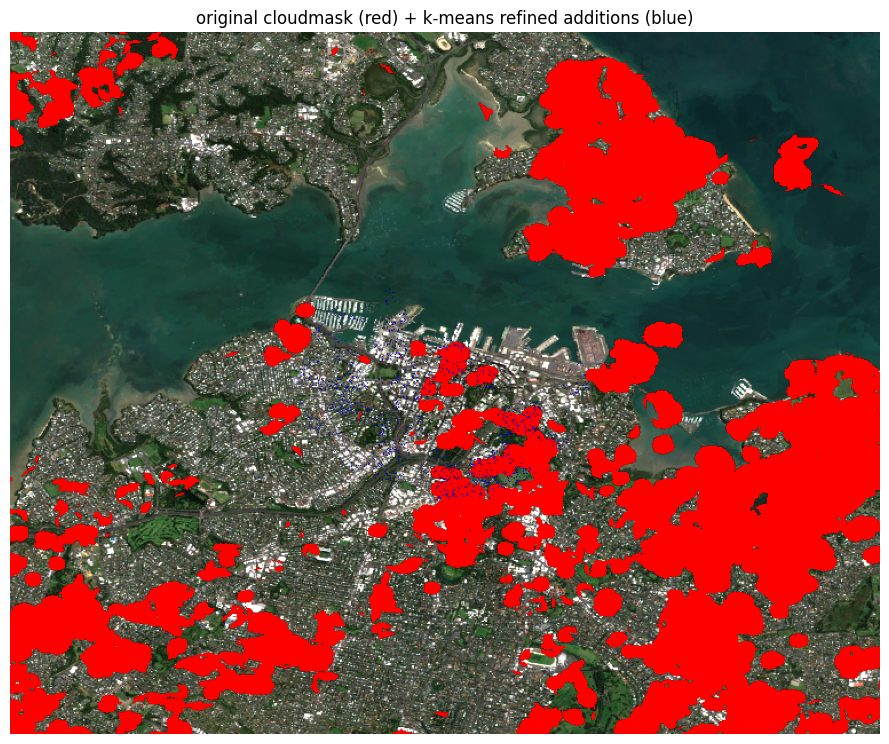

In [31]:
# ---- 报告备用：原掩膜 + k-means 精修点的静态截图 ----
rgb_med = ee_thumb(s2_sr_median, {'bands': ['B4','B3','B2'], 'min': 0, 'max': 2500, 'gamma': 1.1})           # 无云合成底图
lay_orig = ee_thumb(s2_sr_median.select('cloudmask').gt(0.5).selfMask(), {'palette': ['red']})               # 原掩膜（中值>0.5 处）
lay_ref  = ee_thumb(final_mask.selfMask(), {'palette': ['blue']})    # 精修新增点：蓝
plt.figure(figsize=(9, 9))                           # 建图
plt.imshow(rgb_med)                                  # 铺底图
plt.imshow(lay_orig)                                 # 叠原掩膜
plt.imshow(lay_ref)                                  # 叠精修点
plt.title('original cloudmask (red) + k-means refined additions (blue)')         # 标题
plt.axis('off'); plt.tight_layout()                  # 关轴收紧
plt.savefig(f'{FIGDIR}/fig_refined_mask.png', dpi=110, bbox_inches='tight')      # 存盘
plt.show()                                           # 显示

Hopefully, what you should now see above is a patch of downtown Auckland that has your s2cloudless cloudmask and a scatter of blue pixels (i.e. the sample from within the AOI) that k-means has decided is cloud.

Your answer to Q5 should see this scatter of 'new cloudy' pixels be better associated with the known clouds than if you leave it as the default bands that I have provided.





(6) Exercise: take all you have learned in this lab and carry out the following improvements:
1. Increase the K-means sampling to be more representative of the whole scene. This means; sample regions for cloud, clear and cloud edge that are not just over downtown Auckland but from across multiple landcover types.
2. Take the model that you have trained here using SciKitLearn and use it to classify edge pixels across a whole satellite image.

Present your results in **two** figures. The first should show the results of upgrades to pt.1, the second the results of pt.2.

(15 pts)

To get you started on item 2, this might be how you plan out your workflow given that you cannot upload a python ML model directly to Earth Engine:
- Extract cluster centres from Python k-means.
- Pass centres as constants into EE.
- Write a per-pixel classification function assigning nearest cluster centre.
- Apply this function to edge pixels or the whole image as needed.

**（自加）Q6 实现**：两个升级一起做。
1. **采样升级**：范围从市中心一个 2km 圆，扩成四种地表覆盖（市区 / 森林 / 海面 / 农田）各 2.5km；并且在**未抠云的原始镶嵌图**上采样，云区带这才拿到真正的云光谱（讲义原流程在抠过云的图上采样，云区带采到的多是别的日期补进来的地面光谱，这正是可见光波段可分性掉到 0.1σ 的原因）。
2. **模型升级**：晴类横跨水面（极暗）/ 森林（暗）/ 城区（亮）/ 农田，是强多峰分布，k=2 会退化成「一簇吞全场」（实测训练纯度掉到 25.6%、整景 88.5% 被判成云）。改成 **K=8 聚类后按多数票给每簇贴云/晴标签**，并显式 `n_init=10`（新版 sklearn 默认只做 1 次初始化，正是退化的帮凶）。
3. **模型进 EE**：把标准化参数（均值/方差）、8 个簇中心、簇→类映射表全部当常数传进 Earth Engine，逐像元打擂台找最近中心再查表，实现整幅影像的服务器端分类。

In [32]:
# ---- Q6.1：跨地表覆盖采样 ----
WIDE_Q6 = ee.Geometry.Rectangle([174.45, -37.12, 175.05, -36.68])    # 覆盖四个站点的大范围
SITES = {                                            # 四种地表覆盖的采样站点
    'urban':    ee.Geometry.Point(174.7633, -36.8485),               # 市区：奥克兰市中心
    'forest':   ee.Geometry.Point(174.5250, -36.9350),               # 森林：Waitakere 山
    'water':    ee.Geometry.Point(174.9700, -36.7500),               # 海面：Hauraki 湾
    'farmland': ee.Geometry.Point(174.9300, -37.0700),               # 农田：Karaka 牧区
}
s2_sr_cld_col_w6 = get_s2_sr_cld_col(WIDE_Q6, START_DATE, END_DATE)  # 用大范围重新取影像（沿用当前"较差"参数）
s2_raw_mosaic = s2_sr_cld_col_w6.map(add_cld_shdw_mask).mosaic()     # 只加掩膜波段、不抠云 → 云像元保留真实光谱！
cm_w = s2_raw_mosaic.select('cloudmask')             # 掩膜波段
zone_masks = {                                       # 三个采样区带（沿用讲义定义）
    'Cloud': cm_w.selfMask(),                        # 云内部：掩膜=1
    'Clear': cm_w.Not().selfMask(),                  # 晴空内部：掩膜=0
    'Edge':  cm_w.focal_max(20).And(cm_w.Not()),     # 云边缘：外扩 20 像素减云本体
}
SAMPLE_BANDS_W = ['B2', 'B3', 'B4', 'B5', 'B6', 'B9', 'B8', 'B11', 'B12', 'probability']         # 采样波段

def sample_all_sites(zone_mask, seed0):              # 对一个区带、跨全部站点采样并服务器端合并
    fcs = []                                         # 收集各站点样本
    for k, (site, pt) in enumerate(SITES.items()):   # 逐站点
        fc = (s2_raw_mosaic.select(SAMPLE_BANDS_W)   # 选采样波段
              .updateMask(zone_mask)                 # 只留该区带
              .sample(region=pt.buffer(2500), scale=10, numPixels=1200, seed=seed0 + k, geometries=True)     # 站点周边 2.5km
              .map(lambda f, s=site: f.set('site', s)))              # 打上站点标签
        fcs.append(fc)                               # 收进列表
    return ee.FeatureCollection(fcs).flatten()       # 合并成一个要素集（服务器端，只需一次 getInfo）

zone_dfs = {}                                        # 三个区带的本地表
for zi, (zn, zm) in enumerate(zone_masks.items()):   # 逐区带
    zone_dfs[zn] = fc_to_df(sample_all_sites(zm, zi * 10))           # 一次 getInfo 拿到全站点样本
    print(zn, len(zone_dfs[zn]), 'samples; per site:', dict(zone_dfs[zn]['site'].value_counts()))            # 汇报数量
cloud_w_df, clear_w_df, edge_w_df = zone_dfs['Cloud'], zone_dfs['Clear'], zone_dfs['Edge']       # 拆成三张表

Cloud 839 samples; per site: {'forest': np.int64(702), 'urban': np.int64(135), 'farmland': np.int64(2)}


Clear 3941 samples; per site: {'water': np.int64(1200), 'farmland': np.int64(1199), 'urban': np.int64(1039), 'forest': np.int64(503)}


Edge 834 samples; per site: {'urban': np.int64(449), 'forest': np.int64(361), 'farmland': np.int64(24)}


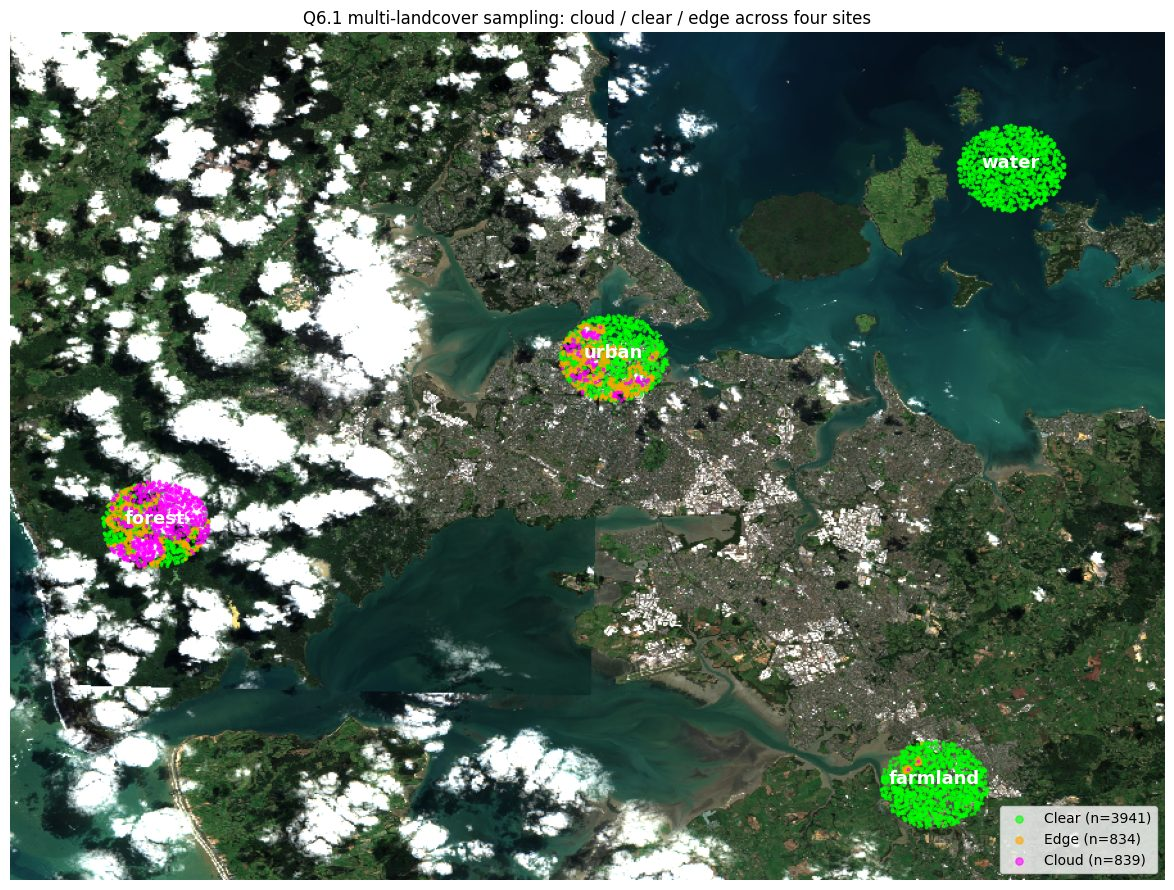

In [33]:
# ---- Q6.1 成果图：大范围底图 + 三类样本的空间分布 ----
rgb_w6 = ee_thumb(s2_raw_mosaic, {'bands': ['B4','B3','B2'], 'min': 0, 'max': 2500, 'gamma': 1.1}, region=WIDE_Q6, dim=900)  # 大范围真彩底图
lonW, lonE, latS, latN = 174.45, 175.05, -37.12, -36.68              # 与 WIDE_Q6 完全一致的经纬边界
H, W = rgb_w6.shape[:2]                              # 底图像素尺寸

def to_px(lon, lat):                                 # 经纬度 → 图上像素（缩略图为等经纬网格，线性映射即可）
    return (lon - lonW) / (lonE - lonW) * W, (latN - lat) / (latN - latS) * H    # x 向东增，y 向南增

plt.figure(figsize=(13, 9))                          # 建图
plt.imshow(rgb_w6)                                   # 铺底图
for df, color, name in [(clear_w_df, 'lime', 'Clear'), (edge_w_df, 'orange', 'Edge'), (cloud_w_df, 'magenta', 'Cloud')]:     # 三类样本
    xs, ys = to_px(df['longitude'].values, df['latitude'].values)    # 批量换算像素坐标
    plt.scatter(xs, ys, s=3, c=color, label=f'{name} (n={len(df)})', alpha=0.6)  # 画散点
for s, pt in SITES.items():                          # 标注四个站点名
    x, y = to_px(*pt.coordinates().getInfo())        # 站点中心的像素位置
    plt.annotate(s, (x, y), color='white', fontsize=13, fontweight='bold', ha='center')          # 白字标注
plt.legend(loc='lower right', markerscale=3)         # 图例（点放大些）
plt.axis('off')                                      # 关轴
plt.title('Q6.1 multi-landcover sampling: cloud / clear / edge across four sites')               # 标题
plt.tight_layout(); plt.savefig(f'{FIGDIR}/fig_q6_sampling.png', dpi=110, bbox_inches='tight'); plt.show()   # 存盘并显示

In [34]:
# ---- Q6：用新样本重训 k-means（升级点：真实云光谱 + 标准化 + 数据选波段 + K=8 簇后贴标）----
from sklearn.preprocessing import StandardScaler     # 特征标准化（消除量纲差异，距离度量才公平）
comb_w = pd.concat([cloud_w_df.assign(**{'class': 'Cloud'}), clear_w_df.assign(**{'class': 'Clear'})])       # 云+晴合并
n_min = comb_w['class'].value_counts().min()         # 少数类数量
bal_w = comb_w.groupby('class').sample(n=n_min, random_state=42)     # 类平衡下采样

rows2 = []                                           # 在新样本上重算一遍波段可分性
for b in BANDS9:                                     # 逐波段
    d_val = abs(cloud_w_df[b].mean() - clear_w_df[b].mean()) / np.sqrt((cloud_w_df[b].var() + clear_w_df[b].var()) / 2)      # Cohen's d
    rows2.append((b, d_val))                         # 收集
rank_w = pd.DataFrame(rows2, columns=['band', 'cohen_d']).sort_values('cohen_d', ascending=False).reset_index(drop=True)     # 排序
print(rank_w.round(2))                               # 打印新排名（真实云光谱下所有波段的 d 都大幅回升）
FEATS_W = list(rank_w['band'].head(4))               # 仍按数据取前 4 波段
print('Q6 k-means features:', FEATS_W)               # 明示选择

scaler = StandardScaler().fit(bal_w[FEATS_W].values) # 拟合标准化参数（均值/方差）
Xw = scaler.transform(bal_w[FEATS_W].values)         # 标准化训练特征
yw = (bal_w['class'] == 'Cloud').astype(int).values  # 标签（只用于给簇贴标，不参与聚类）
K_W = 8                                              # 簇数=8：晴类横跨水面/森林/城区/农田是强多峰分布，k=2 会退化成「一簇吞全场」（实测纯度掉到 25.6%）
km_w = KMeans(n_clusters=K_W, random_state=42, n_init=10).fit(Xw)    # n_init=10：新版 sklearn 默认只跑 1 次初始化，单次容易掉进退化局部最优
cluster_to_class = np.zeros(K_W, int)                # 映射表：每个簇 → 云(1)/晴(0)
for c in range(K_W):                                 # 逐簇
    m = km_w.labels_ == c                            # 该簇的训练样本
    cluster_to_class[c] = 1 if (yw[m].mean() if m.any() else 0) > 0.5 else 0     # 簇内云样本过半 → 云簇（多数票贴标）
purity_w = (cluster_to_class[km_w.labels_] == yw).mean()             # 簇后贴标在训练集上的纯度
print(f'multi-landcover k-means (K={K_W}) purity: {purity_w:.1%}')   # 汇报（对照市中心 k=2 版）

edge_pred_w = km_w.predict(scaler.transform(edge_w_df[FEATS_W].values))          # 边缘样本入簇
edge_w_df['predicted_class'] = np.where(cluster_to_class[edge_pred_w] == 1, 'Cloud', 'Clear')    # 查映射表翻译成类别
print(edge_w_df['predicted_class'].value_counts())   # 边缘分类数量

  band  cohen_d
0   B9     1.37
1  B12     1.31
2   B5     1.26
3   B6     1.23
4   B4     1.22
5   B2     1.21
6   B3     1.19
7  B11     1.17
8   B8     1.15
Q6 k-means features: ['B9', 'B12', 'B5', 'B6']


multi-landcover k-means (K=8) purity: 83.0%
predicted_class
Clear    526
Cloud    308
Name: count, dtype: int64


In [35]:
# ---- Q6.2：把 K=8 的 k-means 搬进 Earth Engine（8 个簇中心当常数，逐像元打擂台找最近中心）----
mean_c = list(scaler.mean_)                          # 标准化均值（转普通 list 传给 EE）
std_c = list(scaler.scale_)                          # 标准化标准差
img_std = s2_raw_mosaic.select(FEATS_W).subtract(ee.Image.constant(mean_c)).divide(ee.Image.constant(std_c)) # 服务器端做同样的标准化
best_d = None                                        # 当前最近距离（逐像元擂台）
best_cls = None                                      # 当前最近簇对应的类别（逐像元）
for c in range(K_W):                                 # 逐个簇中心上擂台
    d_img = img_std.subtract(ee.Image.constant(list(km_w.cluster_centers_[c]))).pow(2).reduce(ee.Reducer.sum())  # 到该中心的距离平方
    c_img = ee.Image.constant(int(cluster_to_class[c]))              # 该簇的类别常数图（查映射表）
    if best_d is None:                               # 第一个中心直接当当前最优
        best_d, best_cls = d_img, c_img              # 初始化擂台
    else:                                            # 之后逐个比较
        closer = d_img.lt(best_d)                    # 该中心更近的像元
        best_cls = best_cls.where(closer, c_img)     # 更近处更新类别
        best_d = best_d.min(d_img)                   # 更新最近距离
kmeans_cloud = best_cls.rename('kmeans_cloud')       # 整图逐像元分类结果（1=云）
frac_cloud = kmeans_cloud.reduceRegion(ee.Reducer.mean(), WIDE_Q6, 120).get('kmeans_cloud').getInfo()        # 云像元占比
print(f'k-means classifies {frac_cloud:.1%} of the whole scene as cloud')        # 汇报

k-means classifies 28.3% of the whole scene as cloud


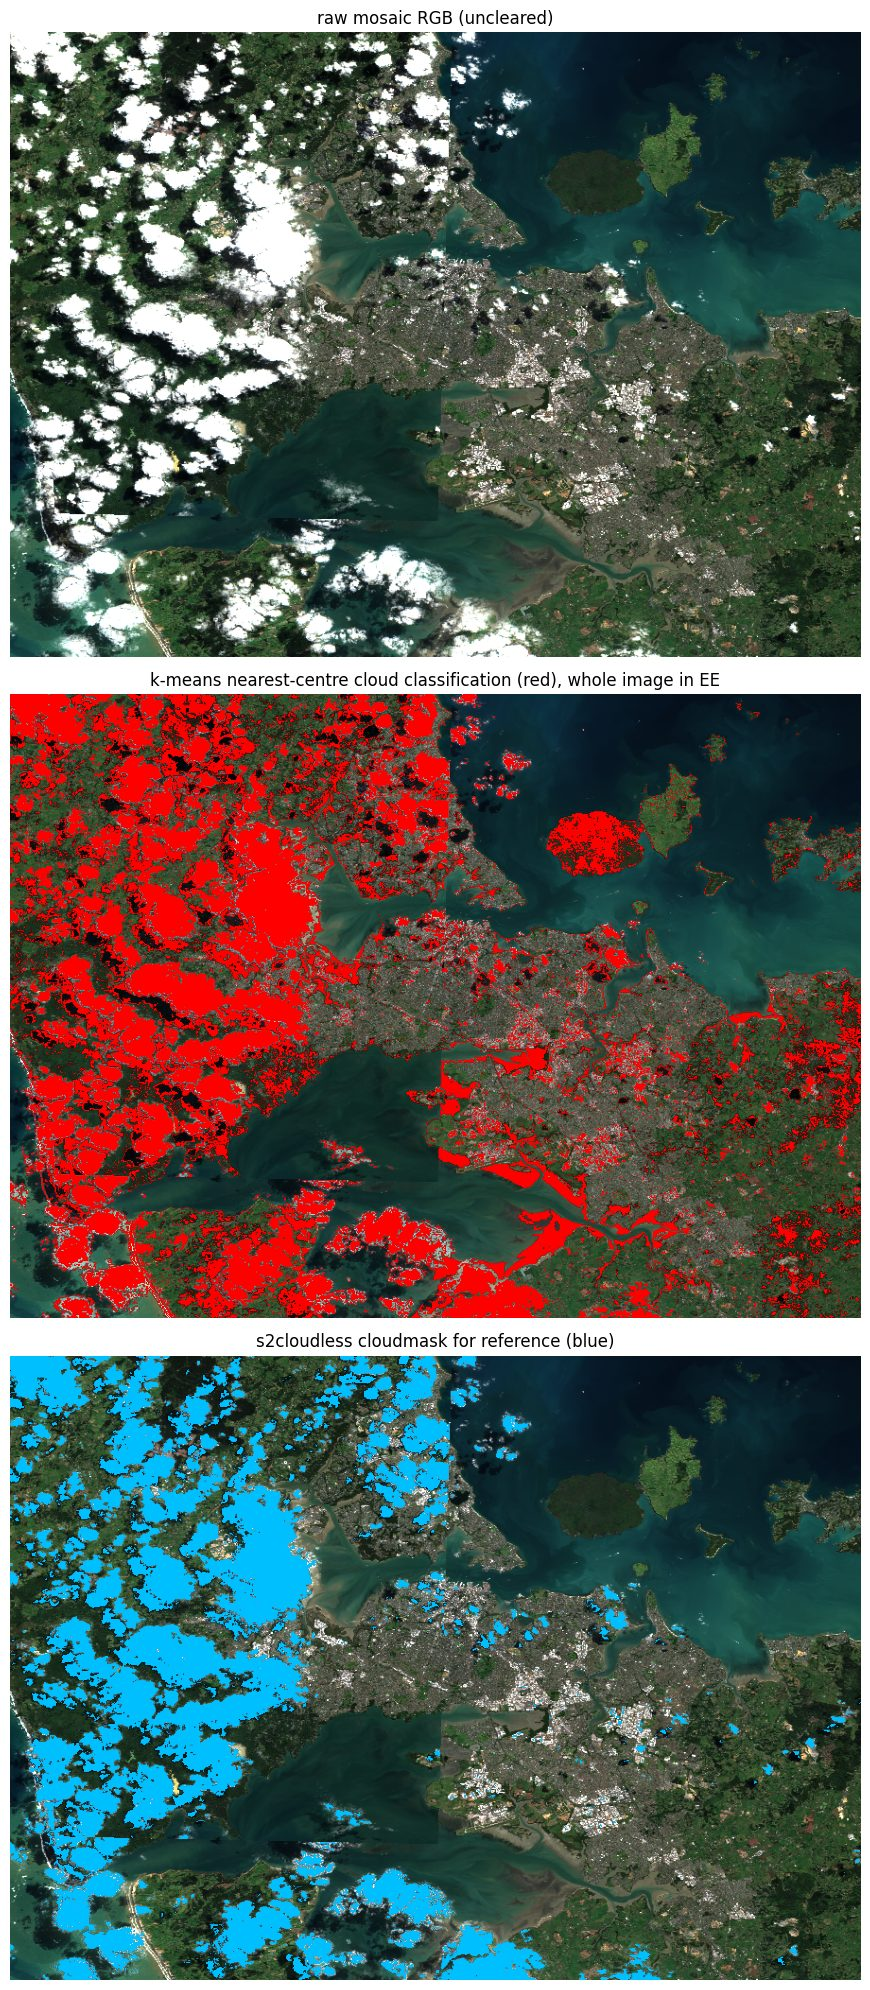

In [36]:
# ---- Q6.2 成果图：整幅影像的 k-means 云分类 vs s2cloudless 掩膜 ----
lay_km  = ee_thumb(kmeans_cloud.selfMask(), {'palette': ['red']}, region=WIDE_Q6, dim=900)       # k-means 判云：红
lay_s2c = ee_thumb(cm_w.selfMask(), {'palette': ['00bfff']}, region=WIDE_Q6, dim=900)            # s2cloudless 掩膜：蓝
fig, axes = plt.subplots(3, 1, figsize=(13, 20))     # 三联竖排（大范围是横长条）
panels = [(None, 'raw mosaic RGB (uncleared)'),      # 上：原始镶嵌图
          (lay_km, 'k-means nearest-centre cloud classification (red), whole image in EE'),      # 中：k-means 整图分类
          (lay_s2c, 's2cloudless cloudmask for reference (blue)')]   # 下：参照掩膜
for ax, (ov, t) in zip(axes, panels):                # 逐面板
    ax.imshow(rgb_w6)                                # 底图
    if ov is not None:                               # 有叠加层就叠
        ax.imshow(ov)                                # 叠加
    ax.set_title(t); ax.axis('off')                  # 标题关轴
plt.tight_layout()                                   # 收紧
plt.savefig(f'{FIGDIR}/fig_q6_wholeimage.png', dpi=110, bbox_inches='tight')     # 存盘（Q6 第二张成果图）
plt.show()                                           # 显示

__ANSWER6_PLACEHOLDER__